Cell 1 — Install & Import

In [1]:
!pip install -q transformers datasets lime accelerate

import pandas as pd
import numpy as np
import re
import os
import random
import time

import torch
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    get_linear_schedule_with_warmup
)

from lime.lime_text import LimeTextExplainer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 20.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


Cell 2 — GPU & Seed

In [2]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

Device: cuda
GPU: Tesla T4


Cell 3 — Dataset Load

In [4]:
df = pd.read_csv("CyberBullyingData.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset Shape: (4000, 3)
Columns: ['Text', 'Label', 'Types']


,Text,Label,Types
0,Stop bombing IRAN ! Is that simple and leave...,Not-Bullying,NaN
1,"Show this video and Ronaldo's stats to him, no...",Not-Bullying,NaN
2,Please do not hit our civilian infrastructure....,Bullying,Religion
3,6:07 bro got something inside his nose,Not-Bullying,NaN
4,This is the kind of content a fan wants to h...,Not-Bullying,NaN


Cell 4 — Dataset Inspection

In [5]:
print("Total Rows:", len(df))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nLabel Distribution:")
print(df["Label"].value_counts())

print("\nType Distribution:")
print(df["Types"].value_counts(dropna=False))

Total Rows: 4000

Missing Values:
Text        0
Label       0
Types    2059
dtype: int64

Duplicate Rows: 0

Label Distribution:
Label
Not-Bullying    2059
Bullying        1941
Name: count, dtype: int64

Type Distribution:
Types
NaN                 2059
Troll                521
Religion             492
Sexual               399
Threat               366
Political            112
Racism/Ethnicity      51
Name: count, dtype: int64


Cell 5 — Cleaning & Preprocessing

In [ ]:
import re

df = df.dropna(subset=["Text"]).copy()
df["Text"] = df["Text"].astype(str)

def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["Text"].apply(clean_text)

df = df.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)

df["binary_label"] = (
    df["Label"]
    .str.strip()
    .str.lower()
    .eq("bullying")
    .astype(int)
)

# Keep the bullying sub-type (Troll / Religion / Sexual / Threat / Political / Racism)
# so we can optionally filter by topic later. Not-Bullying rows get an empty topic.
df["Types"] = df["Types"].fillna("").astype(str).str.strip()

df = df[["clean_text", "binary_label", "Types"]].rename(
    columns={"clean_text": "text", "binary_label": "label", "Types": "topic"}
)

print("Final Dataset:", len(df))
print(df["label"].value_counts())
print(df.head())

In [ ]:
# ============================================================
# Topic Filter (optional) — select related bullying topics
# ============================================================
# Available topics: Troll, Religion, Sexual, Threat, Political, Racism/Ethnicity
#
# SELECTED_TOPICS = None  ->  use ALL topics (full dataset, default)
# SELECTED_TOPICS = ["Religion", "Troll"]  ->  keep all Not-Bullying comments
#                                              + only these bullying topics
SELECTED_TOPICS = None

print("Topic counts (Bullying rows only):")
print(df[df["label"] == 1]["topic"].value_counts())

if SELECTED_TOPICS:
    keep = (df["label"] == 0) | (df["topic"].isin(SELECTED_TOPICS))
    df = df[keep].reset_index(drop=True)
    print("\nSelected topics:", SELECTED_TOPICS)
    print("Rows after topic filter:", len(df))
    print(df["label"].value_counts())
else:
    print("\nUsing ALL topics — full dataset:", len(df))

Cell 6 — Class Distribution

label
0    2059
1    1941
Name: count, dtype: int64


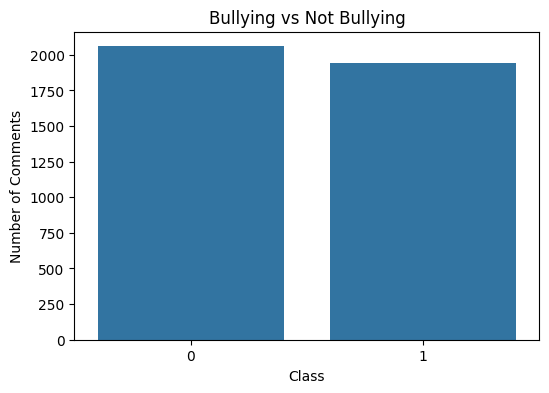

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

print(
    df["label"]
    .value_counts()
)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="label"
)

plt.title(
    "Bullying vs Not Bullying"
)

plt.xlabel("Class")
plt.ylabel("Number of Comments")

plt.show()

Cell 8 — Text Length

count    4000.000000
mean       22.645750
std        17.016893
min         1.000000
25%        10.000000
50%        19.000000
75%        31.000000
max       243.000000
Name: text_length, dtype: float64


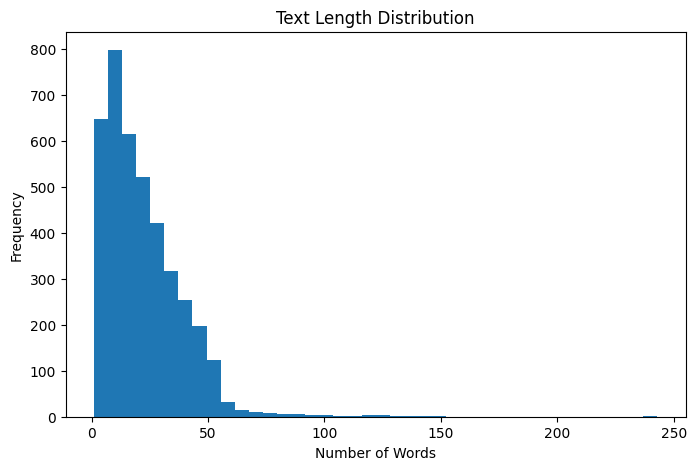

In [15]:
df["text_length"] = (
    df["text"]
    .str.split()
    .str.len()
)

print(
    df["text_length"].describe()
)

plt.figure(figsize=(8, 5))

plt.hist(
    df["text_length"],
    bins=40
)

plt.title(
    "Text Length Distribution"
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

from sklearn.model_selection import train_test_split

# Shuffle the whole dataset before splitting (reproducible with SEED).
# This reorders all rows so the train/val/test split is drawn from a
# freshly shuffled dataset instead of the original CSV order.
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

X = df["text"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

In [16]:
from sklearn.model_selection import train_test_split

X = df["text"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 2800
Validation: 600
Test: 600


Baseline 1 — Logistic Regression
Cell 10 — TF-IDF + Logistic Regression

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import time

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(C=1, max_iter=1000, random_state=SEED)

start = time.time()
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)
lr_time = time.time() - start

lr_acc = accuracy_score(y_test, lr_preds)
lr_prec, lr_rec, lr_f1, _ = precision_recall_fscore_support(y_test, lr_preds, average="weighted")

print("Logistic Regression (tuned, C=1)")
print("Accuracy :", round(lr_acc, 4))
print("Precision:", round(lr_prec, 4))
print("Recall   :", round(lr_rec, 4))
print("F1 Score :", round(lr_f1, 4))

Logistic Regression (tuned, C=1)
Accuracy : 0.8333
Precision: 0.8362
Recall   : 0.8333
F1 Score : 0.8327


Baseline 2 — LSTM

Cell 11 — LSTM Preparation & Training

In [18]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

MAX_WORDS = 10000
MAX_LEN = 100

keras_tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN)
X_val_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_val), maxlen=MAX_LEN)
X_test_seq = pad_sequences(keras_tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN)

lstm_model = Sequential([
    Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
    LSTM(128, return_sequences=True),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])
lstm_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_lstm.h5', monitor='val_loss', save_best_only=True)

lstm_history = lstm_model.fit(
    X_train_seq, y_train,
    validation_data=(X_val_seq, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

lstm_probs = lstm_model.predict(X_test_seq, verbose=0).flatten()
lstm_preds = (lstm_probs >= 0.5).astype(int)

lstm_acc = accuracy_score(y_test, lstm_preds)
lstm_prec, lstm_rec, lstm_f1, _ = precision_recall_fscore_support(y_test, lstm_preds, average="weighted")

print("\nLSTM (tuned, stopped at epoch", len(lstm_history.history['loss']), ")")
print("Accuracy :", round(lstm_acc, 4))
print("Precision:", round(lstm_prec, 4))
print("Recall   :", round(lstm_rec, 4))
print("F1 Score :", round(lstm_f1, 4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6040 - loss: 0.6459

88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.6943 - loss: 0.5691 - val_accuracy: 0.8100 - val_loss: 0.4299
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9010 - loss: 0.2559

88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9161 - loss: 0.2210 - val_accuracy: 0.8633 - val_loss: 0.3161
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9793 - loss: 0.0686 - val_accuracy: 0.8700 - val_loss: 0.3843
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9918 - loss: 0.0247 - val_accuracy: 0.8683 - val_loss: 0.4160
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9982 - loss: 0.0057 - val_accuracy: 0.8650 - val_loss: 0.5106

LSTM (tuned, stopped at epoch 5 )
Accuracy : 0.8733
Precision: 0.8733
Recall   : 0.8733
F1 Score : 0.8733


Baseline 3 — GRU
Cell 12 — GRU Training & Evaluation

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

gru_model = Sequential([
    Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
    GRU(128, return_sequences=True),
    GRU(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])
gru_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop_gru = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint_gru = ModelCheckpoint('best_gru.h5', monitor='val_loss', save_best_only=True)

gru_history = gru_model.fit(
    X_train_seq, y_train,
    validation_data=(X_val_seq, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_gru, checkpoint_gru],
    verbose=1
)

gru_probs = gru_model.predict(X_test_seq, verbose=0).flatten()
gru_preds = (gru_probs >= 0.5).astype(int)

gru_acc = accuracy_score(y_test, gru_preds)
gru_prec, gru_rec, gru_f1, _ = precision_recall_fscore_support(y_test, gru_preds, average="weighted")

print("\nGRU (tuned, stopped at epoch", len(gru_history.history['loss']), ")")
print("Accuracy :", round(gru_acc, 4))
print("Precision:", round(gru_prec, 4))
print("Recall   :", round(gru_rec, 4))
print("F1 Score :", round(gru_f1, 4))

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


86/88 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6401 - loss: 0.6162

88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.7257 - loss: 0.5297 - val_accuracy: 0.8533 - val_loss: 0.3742
Epoch 2/30
84/88 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9347 - loss: 0.1811

88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9296 - loss: 0.1931 - val_accuracy: 0.8633 - val_loss: 0.3392
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9811 - loss: 0.0603 - val_accuracy: 0.8650 - val_loss: 0.5048
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9961 - loss: 0.0124 - val_accuracy: 0.8733 - val_loss: 0.5118
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9989 - loss: 0.0035 - val_accuracy: 0.8567 - val_loss: 0.6509

GRU (tuned, stopped at epoch 5 )
Accuracy : 0.8533
Precision: 0.8536
Recall   : 0.8533
F1 Score : 0.8534


Main Model — RoBERTa

Cell 13 — RoBERTa Setup

In [20]:
from transformers import RobertaTokenizer

MODEL_NAME = "roberta-base"

roberta_tokenizer = (
    RobertaTokenizer
    .from_pretrained(MODEL_NAME)
)

print("RoBERTa tokenizer loaded.")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

RoBERTa tokenizer loaded.


Cell 14 — Dataset & DataLoader

In [21]:
from torch.utils.data import Dataset, DataLoader

class BullyingDataset(Dataset):

    def __init__(
        self,
        texts,
        labels,
        tokenizer,
        max_len=128
    ):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            str(self.texts[idx]),
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "labels":
                torch.tensor(
                    self.labels[idx],
                    dtype=torch.long
                )
        }


train_dataset = BullyingDataset(
    X_train,
    y_train,
    roberta_tokenizer
)

val_dataset = BullyingDataset(
    X_val,
    y_val,
    roberta_tokenizer
)

test_dataset = BullyingDataset(
    X_test,
    y_test,
    roberta_tokenizer
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32
)

print("DataLoaders ready.")

DataLoaders ready.


Cell 15 — RoBERTa Training

In [22]:
from transformers import RobertaForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score
import torch
import time

roberta_model = RobertaForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
optimizer = torch.optim.AdamW(roberta_model.parameters(), lr=2e-5)

EPOCHS = 6
PATIENCE = 2

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

best_val_loss = float("inf")
epochs_no_improve = 0

print("Starting RoBERTa training (lr=2e-5)...")

for epoch in range(EPOCHS):
    start_time = time.time()
    roberta_model.train()
    total_train_loss = 0
    for step, batch in enumerate(train_loader):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        outputs = roberta_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(roberta_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_train_loss += loss.item()
        if (step + 1) % 25 == 0 or (step + 1) == len(train_loader):
            print(f"Epoch {epoch+1}/{EPOCHS} | Step {step+1}/{len(train_loader)} | Loss: {loss.item():.4f}")

    train_loss = total_train_loss / len(train_loader)

    roberta_model.eval()
    total_val_loss = 0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            outputs = roberta_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            total_val_loss += outputs.loss.item()
            val_preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss = total_val_loss / len(val_loader)
    val_acc = accuracy_score(val_labels, val_preds)
    epoch_time = time.time() - start_time

    print("\n" + "=" * 60)
    print(f"Epoch {epoch+1}/{EPOCHS} completed")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}  |  Validation Accuracy: {val_acc:.4f}")
    print(f"Time: {epoch_time/60:.2f} minutes")
    print("=" * 60)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(roberta_model.state_dict(), "best_roberta_lr2e5.pt")
        print("Best model saved!")
    else:
        epochs_no_improve += 1
        print(f"No improvement for {epochs_no_improve} epoch(s)")
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            break

print("\nTraining finished. Best validation loss:", round(best_val_loss, 4))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting RoBERTa training (lr=2e-5)...
Epoch 1/6 | Step 25/88 | Loss: 0.3567
Epoch 1/6 | Step 50/88 | Loss: 0.1668
Epoch 1/6 | Step 75/88 | Loss: 0.1717
Epoch 1/6 | Step 88/88 | Loss: 0.2374

Epoch 1/6 completed
Train Loss: 0.3727
Validation Loss: 0.1838  |  Validation Accuracy: 0.9200
Time: 0.94 minutes
Best model saved!
Epoch 2/6 | Step 25/88 | Loss: 0.1588
Epoch 2/6 | Step 50/88 | Loss: 0.0627
Epoch 2/6 | Step 75/88 | Loss: 0.4229
Epoch 2/6 | Step 88/88 | Loss: 0.0347

Epoch 2/6 completed
Train Loss: 0.1854
Validation Loss: 0.2428  |  Validation Accuracy: 0.9250
Time: 1.02 minutes
No improvement for 1 epoch(s)
Epoch 3/6 | Step 25/88 | Loss: 0.0249
Epoch 3/6 | Step 50/88 | Loss: 0.0351
Epoch 3/6 | Step 75/88 | Loss: 0.1514
Epoch 3/6 | Step 88/88 | Loss: 0.0096

Epoch 3/6 completed
Train Loss: 0.0970
Validation Loss: 0.2385  |  Validation Accuracy: 0.9317
Time: 1.01 minutes
No improvement for 2 epoch(s)

Early stopping triggered at epoch 3

Training finished. Best validation loss: 0.1

Cell 16 — RoBERTa Evaluation

In [23]:
roberta_model.load_state_dict(torch.load("best_roberta_lr2e5.pt"))
roberta_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        outputs = roberta_model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

from sklearn.metrics import precision_recall_fscore_support
acc = accuracy_score(all_labels, all_preds)
prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="weighted")
print("RoBERTa (lr=2e-5)")
print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1 Score :", round(f1, 4))

RoBERTa (lr=2e-5)
Accuracy : 0.9233
Precision: 0.9236
Recall   : 0.9233
F1 Score : 0.9233


Comparison

Cell 17 — Model Comparison

In [24]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_acc,
        "Precision": lr_prec,
        "Recall": lr_rec,
        "F1-Score": lr_f1
    },

    {
        "Model": "LSTM",
        "Accuracy": lstm_acc,
        "Precision": lstm_prec,
        "Recall": lstm_rec,
        "F1-Score": lstm_f1
    },

    {
        "Model": "GRU",
        "Accuracy": gru_acc,
        "Precision": gru_prec,
        "Recall": gru_rec,
        "F1-Score": gru_f1
    },

    {
        "Model": "RoBERTa",
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    }
])

results_display = results.copy()

for col in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]:

    results_display[col] = (
        results_display[col] * 100
    ).round(2)

display(results_display)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,83.33,83.62,83.33,83.27
1,LSTM,87.33,87.33,87.33,87.33
2,GRU,85.33,85.36,85.33,85.34
3,RoBERTa,92.33,92.36,92.33,92.33


LR,LSTM & GRU Confution matrix


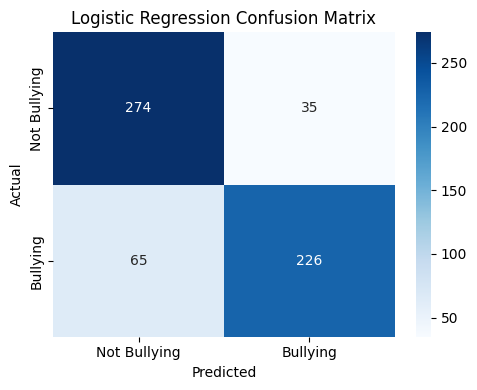

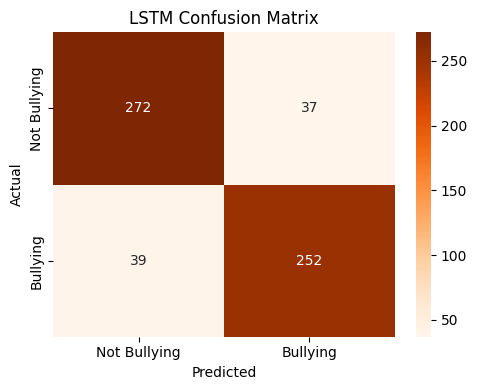

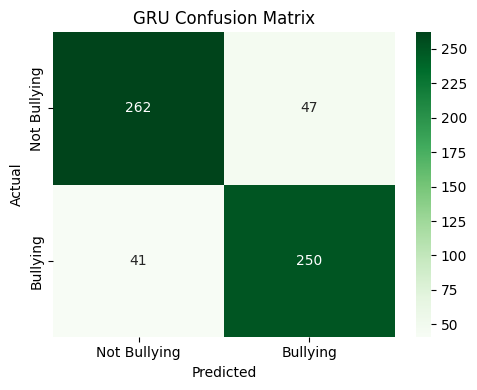

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_cm(y_true, y_pred, title, cmap):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=['Not Bullying','Bullying'],
                yticklabels=['Not Bullying','Bullying'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.savefig(title.replace(' ','_') + '.png', dpi=150)
    plt.show()

# Logistic Regression
plot_cm(y_test, lr_preds, "Logistic Regression Confusion Matrix", "Blues")

# LSTM
plot_cm(y_test, lstm_preds, "LSTM Confusion Matrix", "Oranges")

# GRU
plot_cm(y_test, gru_preds, "GRU Confusion Matrix", "Greens")

Cell 18 — Roberta Confusion Matrix + Model Comparison Graph

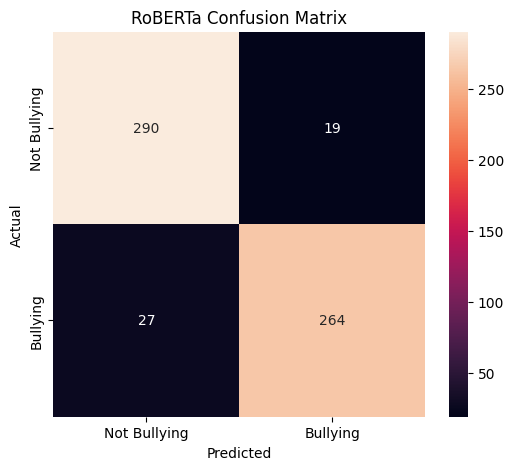

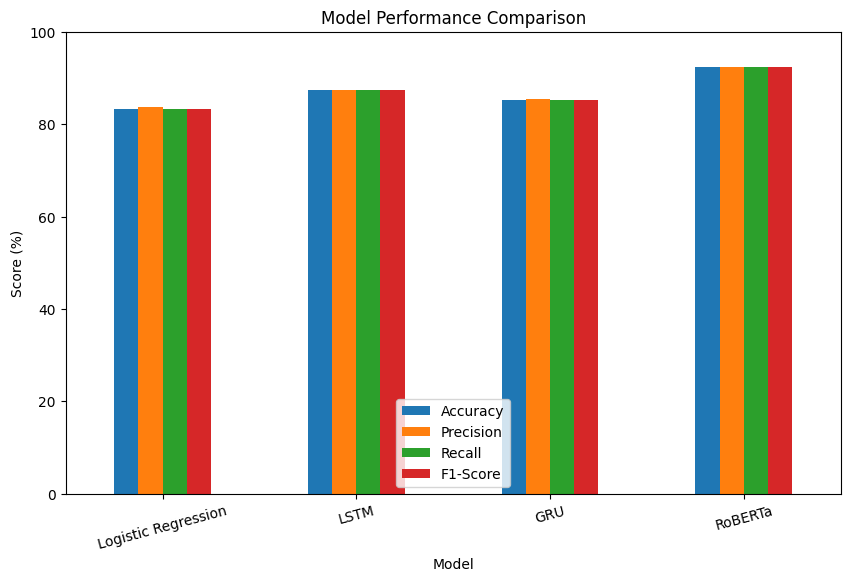

In [28]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Not Bullying",
        "Bullying"
    ],
    yticklabels=[
        "Not Bullying",
        "Bullying"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RoBERTa Confusion Matrix")

plt.show()


results_display.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score (%)")

plt.ylim(0, 100)

plt.xticks(
    rotation=15
)

plt.show()

Cell 26 — Binary LIME Explanation Only


Enter a comment (type 'exit' to stop): Everyone hates you, just go away

-----------------------------------------------------------------
Comment:
Everyone hates you, just go away

Binary Prediction: Bullying
Binary Confidence: 93.30%

Generating LIME explanation...

Important Words:
-----------------------------------------------------------------
hates                    +0.3688 → Bullying
you                      +0.3189 → Bullying
away                     +0.2388 → Bullying
Everyone                 +0.2127 → Bullying
go                       +0.1177 → Bullying
just                     +0.0595 → Bullying
-----------------------------------------------------------------

LIME Explanation Graph:


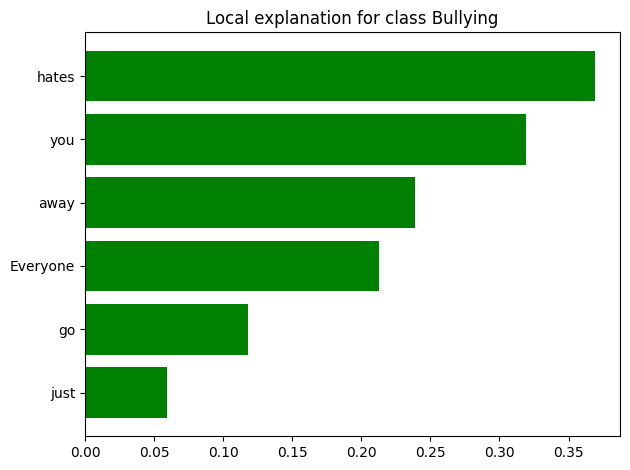


✅ Explanation completed.
You can enter another comment.

Enter a comment (type 'exit' to stop): rubbish boy

-----------------------------------------------------------------
Comment:
rubbish boy

Binary Prediction: Bullying
Binary Confidence: 67.97%

Generating LIME explanation...

Important Words:
-----------------------------------------------------------------
rubbish                  +0.2321 → Bullying
boy                      +0.1427 → Bullying
-----------------------------------------------------------------

LIME Explanation Graph:


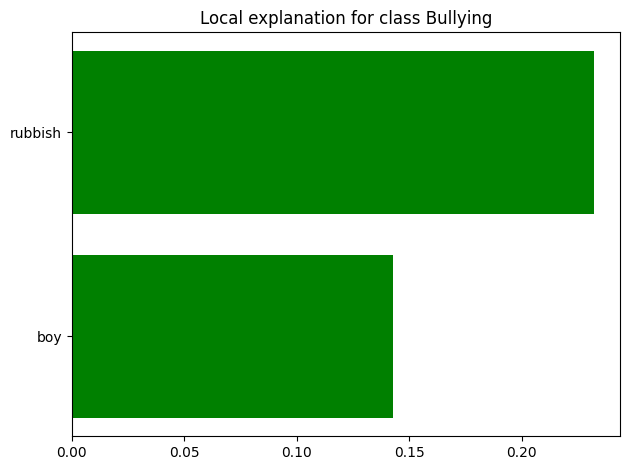


✅ Explanation completed.
You can enter another comment.

Enter a comment (type 'exit' to stop): I don't agree with your opinion

-----------------------------------------------------------------
Comment:
I don't agree with your opinion

Binary Prediction: Not-Bullying
Binary Confidence: 97.07%

Generating LIME explanation...

Important Words:
-----------------------------------------------------------------
opinion                  -0.0269 → Not-Bullying
agree                    -0.0211 → Not-Bullying
don                      +0.0200 → Bullying
with                     -0.0063 → Not-Bullying
t                        +0.0061 → Bullying
I                        +0.0061 → Bullying
your                     +0.0060 → Bullying
-----------------------------------------------------------------

LIME Explanation Graph:


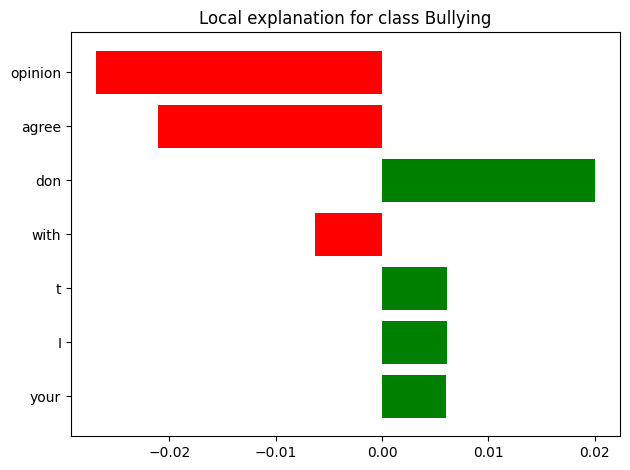


✅ Explanation completed.
You can enter another comment.

Enter a comment (type 'exit' to stop): Wow, you're really smart... said no one ever.

-----------------------------------------------------------------
Comment:
Wow, you're really smart... said no one ever.

Binary Prediction: Not-Bullying
Binary Confidence: 95.32%

Generating LIME explanation...

Important Words:
-----------------------------------------------------------------
Wow                      -0.0298 → Not-Bullying
really                   -0.0236 → Not-Bullying
said                     -0.0200 → Not-Bullying
no                       +0.0186 → Bullying
ever                     +0.0186 → Bullying
smart                    +0.0177 → Bullying
you                      +0.0171 → Bullying
one                      -0.0159 → Not-Bullying
re                       -0.0118 → Not-Bullying
-----------------------------------------------------------------

LIME Explanation Graph:


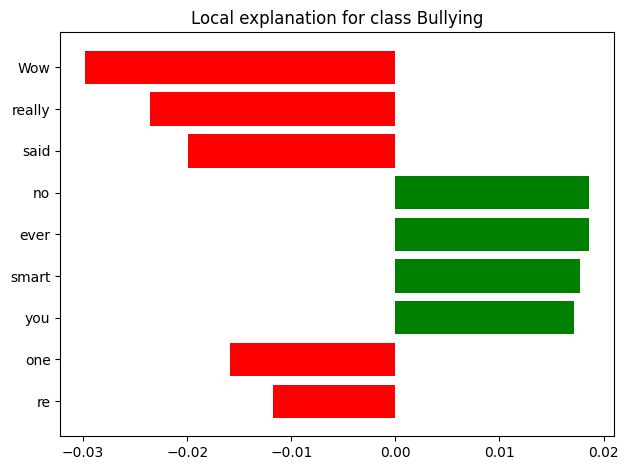


✅ Explanation completed.
You can enter another comment.

Enter a comment (type 'exit' to stop): Nobody asked for your stupid opinion.

-----------------------------------------------------------------
Comment:
Nobody asked for your stupid opinion.

Binary Prediction: Bullying
Binary Confidence: 98.42%

Generating LIME explanation...

Important Words:
-----------------------------------------------------------------
stupid                   +0.9156 → Bullying
your                     +0.0180 → Bullying
asked                    -0.0140 → Not-Bullying
opinion                  -0.0115 → Not-Bullying
Nobody                   -0.0053 → Not-Bullying
for                      +0.0020 → Bullying
-----------------------------------------------------------------

LIME Explanation Graph:


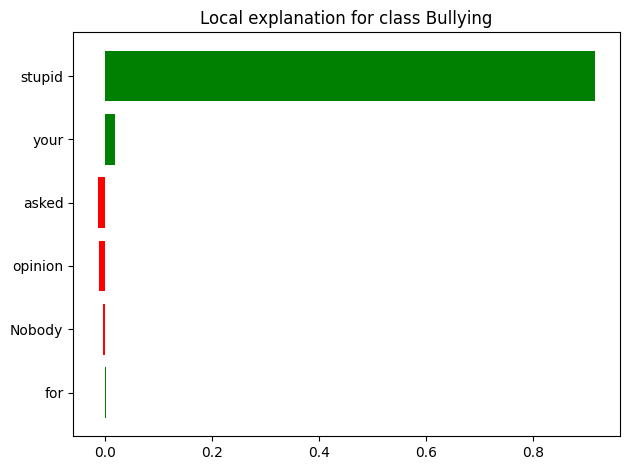


✅ Explanation completed.
You can enter another comment.

Enter a comment (type 'exit' to stop): exit

System stopped.


In [29]:
import torch
import numpy as np
from lime.lime_text import LimeTextExplainer
import matplotlib.pyplot as plt

# Define class names
class_names = ["Not-Bullying", "Bullying"]

# Define a prediction function for LIME
def roberta_predict_proba(texts):
    # Ensure roberta_model and roberta_tokenizer are in scope or passed
    global roberta_model, roberta_tokenizer, device

    # Prepare the model for evaluation
    roberta_model.eval()

    # Process texts in batches to be efficient
    # LIME generates many perturbed samples, so batching is important
    batch_size = 32 # You can adjust this batch size
    probabilities = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        encodings = roberta_tokenizer(
            batch_texts,
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        input_ids = encodings["input_ids"].to(device)
        attention_mask = encodings["attention_mask"].to(device)

        with torch.no_grad():
            outputs = roberta_model(input_ids=input_ids, attention_mask=attention_mask)
            # Apply softmax to logits to get probabilities
            probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()
            probabilities.extend(probs)

    return np.array(probabilities)

# Initialize LIME Explainer
explainer = LimeTextExplainer(class_names=class_names)

# ==========================================
# CELL 26: BINARY LIME - USER INPUT
# ==========================================

while True:

    print("\n" + "=" * 65)

    user_text = input(
        "Enter a comment (type 'exit' to stop): "
    )

    # --------------------------------------
    # EXIT
    # --------------------------------------

    if user_text.strip().lower() == "exit":

        print("\nSystem stopped.")

        break


    # --------------------------------------
    # EMPTY INPUT
    # --------------------------------------

    if not user_text.strip():

        print("\nPlease enter a comment.")

        continue


    # --------------------------------------
    # BINARY PREDICTION
    # --------------------------------------

    probabilities = roberta_predict_proba(
        [user_text]
    )[0]

    prediction = np.argmax(
        probabilities
    )

    confidence = (
        probabilities[prediction] * 100
    )


    # --------------------------------------
    # RESULT
    # --------------------------------------

    print("\n" + "-" * 65)

    print("Comment:")
    print(user_text)

    print(
        "\nBinary Prediction:",
        class_names[prediction]
    )

    print(
        "Binary Confidence:",
        f"{confidence:.2f}%"
    )


    # --------------------------------------
    # LIME EXPLANATION
    # --------------------------------------

    print(
        "\nGenerating LIME explanation..."
    )

    explanation = explainer.explain_instance(
        user_text,
        roberta_predict_proba,
        num_features=10,
        num_samples=500
    )


    # --------------------------------------
    # IMPORTANT WORDS
    # --------------------------------------

    print("\nImportant Words:")

    print("-" * 65)

    for word, weight in explanation.as_list():

        if weight > 0:

            direction = "→ Bullying"

        else:

            direction = "→ Not-Bullying"


        print(
            f"{word:25s}"
            f"{weight:+.4f} "
            f"{direction}"
        )

    print("-" * 65)


    # --------------------------------------
    # LIME GRAPH
    # --------------------------------------

    print(
        "\nLIME Explanation Graph:"
    )

    explanation.as_pyplot_figure()

    plt.tight_layout()

    plt.show()


    # --------------------------------------
    # NEXT COMMENT
    # --------------------------------------

    print(
        "\n✅ Explanation completed."
    )

    print(
        "You can enter another comment."
    )